# 22. From spending announcements to cash actually paid

A government can announce a programme, approve its budget, sign a contract and transfer money on four different dates. An announcement of 100 million crowns does not mean that 100 million has reached a supplier. An economist measuring fiscal activity needs to decide which stage is relevant before asking a model to read the documents.

Here **implemented spending** means cash paid to an outside recipient. Approvals, commitments and promises do not count. A subsequent cancellation stops future authority but does not refund earlier payments. A correction can revise the amount that was previously reported without creating a new payment.

For an illustrative programme, an announcement of 100, approval of 80, payment of 20 and later cancellation imply 20 million of cash paid. The active spending authority is then zero. Adding the four document amounts, or using the last amount alone, answers the wrong question.

This notebook compares asking a model directly for quarter-end totals with asking it to extract an event ledger that Python reconciles. Both methods receive exactly the same documents. The aim is to test the handling of fiscal stages and dates, rather than to estimate the causal effect of spending on the economy.

## Question and summary

Can an event ledger reduce errors in cumulative cash spending relative to a direct answer? We use 12 development histories and 48 held-out histories, two models and two methods. Each history contains fictional documents with amounts and dates generated in code. Qwen authors reusable wording templates; OpenAI and Anthropic models are evaluated. The three quarter-end totals are reconstructed using information published by one fixed as-of date, 30 September 2026. These are retrospective measurements, not contemporaneous forecasts.

GPT-6.1 Sol: direct 48/48 and ledger 48/48 exact cash histories; Claude Opus 5.5: direct 47/48 and ledger 48/48 exact cash histories. All 191 schema-valid held-out answers have zero cash error. There is 1 invalid output among 192 held-out responses. The invalid answer contains the correct cash, authority and status values but begins with prose. The sample contains explicit synthetic records and only six recurring history structures; it does not establish equal performance on public fiscal documents.

## Contents

- [1. Setup and safeguards](#1.-Setup-and-safeguards)
- [2. Fresh fictional histories](#2.-Fresh-fictional-histories)
- [3. Equal evidence and two methods](#3.-Equal-evidence-and-two-methods)
- [4. Development and frozen evaluation](#4.-Development-and-frozen-evaluation)
- [5. Results and uncertainty](#5.-Results-and-uncertainty)
- [6. Worked cases and error analysis](#6.-Worked-cases-and-error-analysis)
- [7. Limits and practical use](#7.-Limits-and-practical-use)
- [8. Reproduction and spend](#8.-Reproduction-and-spend)
- [9. Future work and further reading](#9.-Future-work-and-further-reading)

```mermaid
flowchart LR
    F["Python facts + Qwen wording templates<br/>60 new policy histories"] --> P["Publication-date filter<br/>same documents in each arm"]
    P --> D["Direct totals<br/>2 models × 60 calls"]
    P --> L["Event extraction<br/>2 models × 60 calls"]
    L --> R["Python chronology and reconciliation<br/>3 quarter-end totals per history"]
    D --> S["Exact transaction gold<br/>12 development + 48 held-out histories"]
    R --> S
    S --> O["Cash errors, fiscal-stage errors, intervals<br/>cached responses and figures"]
```

One history travels down both branches. A document that merely repeats a March transfer still refers to the same payment. The ledger branch must identify that reference; the Python step then counts the payment once. The direct branch must return the same quarterly totals without the ledger step. All 48 held-out histories remain in the scoring denominator, including malformed answers.

## 1. Setup and safeguards

The default run is an offline replay. A missing response causes an error rather than an unexpected charge. Live mode defaults to two development and two test histories; the published profile is an explicit choice. Calls are isolated from the repository and have no tools or browsing. The Claude cap below concerns the CLI's reported list-price equivalent. Codex subscription usage has no observable dollar charge per call here.

Every request includes its exact prompt, model identifier and CLI options in its cache key. A raw transport failure remains a result; the run does not silently replace it with a better answer.

In [1]:
import hashlib, json, math, os, platform, random, re, shutil, string, subprocess, tempfile, threading, time
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT=Path.cwd(); DATA=ROOT/'data'; FIG=ROOT/'figures'
DATA.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
LIVE=os.environ.get('NB_LIVE')=='1'
PROFILE=os.environ.get('NB_FISCAL_PROFILE','smoke' if LIVE else 'published')
STAGE=os.environ.get('NB_FISCAL_STAGE','all')
assert PROFILE in ('smoke','published') and STAGE in ('dev','all')
N_DEV,N_TEST=(12,48) if PROFILE=='published' else (2,2)
MODELS={'GPT-6.1 Sol':('codex','gpt-6.1-sol'),'Claude Opus 5.5':('claude','claude-opus-5-5')}
METHODS=['direct','ledger']
MAX_NEW_CALLS=int(os.environ.get('NB_MAX_CALLS','240' if PROFILE=='published' else '16'))
MAX_CLAUDE_LIST_USD=float(os.environ.get('NB_MAX_CLAUDE_LIST_USD','20' if PROFILE=='published' else '2'))
MAX_AUTHOR_USD=1.0; PER_CALL_CLAUDE_USD=0.25
WORKERS=min(3,int(os.environ.get('NB_WORKERS','3')))
PROTOCOL='nb22-fiscal-v1.0'; SEED=22061022
CREATED_AT='2026-10-22'; AS_OF='2026-09-30'
QUARTERS=['2026-03-31','2026-06-30','2026-09-30']
OUT=DATA if PROFILE=='published' else DATA/'smoke'; OUT.mkdir(exist_ok=True)
if PROFILE=='smoke': FIG=FIG/'smoke'; FIG.mkdir(exist_ok=True)
CODEX_OPTIONS=['exec','--skip-git-repo-check','--ephemeral','--ignore-user-config','--sandbox','read-only',
 '--disable','shell_tool','--disable','unified_exec','--disable','apps','--disable','plugins',
 '--disable','multi_agent','--disable','browser_use','--disable','computer_use','--disable','image_generation',
 '--disable','code_mode','--disable','code_mode_host','--disable','shell_snapshot',
 '-c','web_search="disabled"','-c','model_reasoning_effort="low"','--json']
CLAUDE_OPTIONS=['-p','--tools','','--safe-mode','--no-session-persistence','--output-format','json',
 '--effort','low','--max-budget-usd',str(PER_CALL_CLAUDE_USD)]
OPTIONS={'codex':CODEX_OPTIONS,'claude':CLAUDE_OPTIONS}
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':160,'savefig.bbox':'tight','font.size':11,
 'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,
 'axes.axisbelow':True,'axes.titlelocation':'left','figure.facecolor':'white',
 'axes.prop_cycle':plt.cycler(color=['#286895','#cc713a','#32846b','#875e9f'])})
pd.set_option('display.max_colwidth',110)
def canonical(x): return json.dumps(x,sort_keys=True,ensure_ascii=False,separators=(',',':'))
def digest(x): return hashlib.sha256(canonical(x).encode()).hexdigest()
def dump(path,x): path.write_text(json.dumps(x,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
def frozen(name,x):
    p=DATA/name
    if p.exists(): assert canonical(json.loads(p.read_text(encoding='utf-8')))==canonical(x), 'Frozen input changed: '+name
    elif LIVE: dump(p,x)
    else: raise RuntimeError('Missing frozen input: '+name)
    return x
def parse_json(s):
    s=s.strip()
    if s.startswith('```') and s.endswith('```'): s=re.sub(r'^```(?:json)?\s*','',s)[:-3].strip()
    return json.loads(s)
CACHE_PATH=DATA/'cache_requests.jsonl'; CACHE={}; cache_lock=threading.Lock(); new_calls=0; active_claude=0
if CACHE_PATH.exists():
    for line in CACHE_PATH.read_text(encoding='utf-8').splitlines():
        row=json.loads(line); assert row['key']==digest(row['request']); assert row['key'] not in CACHE
        CACHE[row['key']]=row
def transport(req):
    assert LIVE, 'Offline transport is forbidden'
    with tempfile.TemporaryDirectory(prefix='nb22_fiscal_') as tmp:
        backend=req['backend']; exe=shutil.which(backend+'.cmd') or shutil.which(backend)
        if not exe: raise RuntimeError('Missing CLI '+backend)
        cmd=[exe,*req['cli_options']]+(['--model',req['model']] if backend=='claude' else ['-m',req['model'],'-'])
        p=subprocess.run(cmd,input=req['prompt'],text=True,encoding='utf-8',capture_output=True,cwd=tmp,timeout=300)
        if backend=='claude':
            obj=json.loads(p.stdout)
            return dict(text=obj.get('result',''),raw=obj,returncode=p.returncode,is_error=obj.get('is_error',False),
                        usage=obj.get('usage',{}),list_cost_usd=obj.get('total_cost_usd'),stderr=p.stderr[-1500:])
        ev=[json.loads(s) for s in p.stdout.splitlines() if s.startswith('{')]
        items=[e['item'] for e in ev if e.get('type')=='item.completed']
        assert not [i for i in items if i.get('type') not in ('agent_message','reasoning','error')], 'Unexpected tool use'
        answers=[i['text'] for i in items if i.get('type')=='agent_message']
        return dict(text=answers[-1] if answers else '',raw=ev,returncode=p.returncode,
                    usage=next((e['usage'] for e in ev if e.get('type')=='turn.completed'),{}),stderr=p.stderr[-1500:])
def ask(model,prompt):
    global new_calls,active_claude
    backend,mid=MODELS[model]; req=dict(protocol=PROTOCOL,backend=backend,model=mid,prompt=prompt,cli_options=OPTIONS[backend])
    key=digest(req)
    if key in CACHE: return CACHE[key]
    if not LIVE: raise RuntimeError('Offline cache miss '+key)
    with cache_lock:
        spent=sum((r['response'].get('list_cost_usd') if r['response'].get('list_cost_usd') is not None else PER_CALL_CLAUDE_USD)
                  for r in CACHE.values() if r['request']['backend']=='claude')
        if new_calls>=MAX_NEW_CALLS: raise RuntimeError('Call cap reached')
        if backend=='claude' and spent+(active_claude+1)*PER_CALL_CLAUDE_USD>MAX_CLAUDE_LIST_USD:
            raise RuntimeError('Claude reservation cap reached')
        new_calls+=1; active_claude+=backend=='claude'
    start=time.perf_counter()
    try: out=transport(req)
    except Exception as exc: out=dict(text='',error=type(exc).__name__+': '+str(exc)[:1500],usage=None)
    out.update(latency_s=time.perf_counter()-start,collected_at=datetime.now(timezone.utc).isoformat())
    row=dict(key=key,request=req,response=out)
    with cache_lock:
        CACHE[key]=row
        with CACHE_PATH.open('a',encoding='utf-8') as f: f.write(json.dumps(row,ensure_ascii=False)+'\n'); f.flush()
        active_claude-=backend=='claude'
    return row
print('Mode:', 'LIVE' if LIVE else 'OFFLINE', '| Profile:',PROFILE,'| Stage:',STAGE)
print('Sample:',N_DEV,'development +',N_TEST,'held-out histories; workers:',WORKERS)

Mode: OFFLINE | Profile: published | Stage: all
Sample: 12 development + 48 held-out histories; workers: 3


## 2. Fresh fictional histories

The facts are newly generated on 22 October 2026. Dates inside a document belong to a fictional accounting year and are not claims about when the document was created. No public historical test labels are used. The evaluated models therefore cannot have memorized these cases before training. We record GPT-6.1 Sol's published cutoff of 30 April 2026 and Claude Opus 5.5's release date of 22 September 2026; the latter is a release-date fallback, not a claimed training cutoff.

Python supplies monetary facts, project identities and the correct cash transactions. A different vendor, Qwen, writes reusable sentence templates with checked placeholders. It neither selects amounts nor supplies the scoring labels. The frozen authoring response is included for inspection. Template reuse limits language diversity.

Each history belongs to one of six families: announcements without payment, repeated installments, cuts and cancellation, corrected historical amounts, reporting-date traps, and two-project notices. Every family has two development and eight test histories. A document published on 2 October is stored as a leakage check and is excluded from both prompts. The 30 September cutoff applies to publication; quarter assignment applies to the cash settlement date.

In [2]:
TEMPLATE_SPECS={
 'announce':('project amount date','A proposed funding announcement on date of amount million crowns for project. No approval, contract or cash payment has occurred.'),
 'authorize':('project amount date','Effective date, total active spending authority for project becomes amount million crowns. This is a total ceiling, not an increment or a cash payment.'),
 'payment':('project amount date id','A settled external cash transfer of amount million crowns for project with payment reference id and settlement date date. Reporting may occur later.'),
 'cumulative':('project amount date id','Checkpoint id reports cumulative cash paid for project through date as amount million crowns. Includes all earlier payments; not an additional transfer.'),
 'revise_payment':('project amount date id','An accounting correction replaces the earlier amount of payment reference id with amount million crowns for project, settled on date. Not a new transfer or refund.'),
 'revise_cumulative':('project amount date id','Corrected checkpoint id replaces its earlier cumulative cash total for project through date with amount million crowns. Not new spending.'),
 'cancel':('project date','From date the project is cancelled and active spending authority is zero. Earlier cash payments are retained by recipients, without refund.'),
 'cut':('project amount date','From date the total active spending authority for project is reduced to amount million crowns. Earlier payments are not refunded. This is not a cash transfer.'),
 'contract':('project amount date','A contract for project worth amount million crowns was signed on date, but it remains entirely unpaid. This does not change the already stated budget authority.'),
 'pending':('project amount date','A cash payment for project of amount million crowns is proposed for date but has not settled. Do not describe it as money already paid.'),
 'combined':('project amount date id other otheramount total','A joint settlement on date paid total million crowns: amount for project under reference id and otheramount for other. The project amount is only its own share.'),
}
AUTHOR_MODEL='qwen/qwen3.8-flash-20260826'
author_prompt="""Write JSON only: an object mapping each requested kind to a list of TWO distinct short factual government bulletin templates. All amounts are in million crowns. Preserve the exact semantics. Each template must contain EACH named placeholder exactly once, in braces, and no other braces. Do not add facts, dates, numbers, source headings or commentary. Plain English. Make the variants different enough to read naturally. No implicit cash payment for a proposal, authority or contract. Template specifications:\n"""+json.dumps(TEMPLATE_SPECS)
author_req=dict(model=AUTHOR_MODEL,messages=[{'role':'user','content':author_prompt}],temperature=.6,max_tokens=4500,
                reasoning={'enabled':False},response_format={'type':'json_object'},usage={'include':True})
author_path=DATA/'authoring_cache.json'
if author_path.exists():
    author_cache=json.loads(author_path.read_text(encoding='utf-8')); assert author_cache['key']==digest(author_req)
else:
    assert LIVE, 'Missing authored templates'
    import requests
    key=os.environ.get('OPENROUTER_API_KEY'); assert key, 'OPENROUTER_API_KEY unavailable'
    catalog=requests.get('https://openrouter.ai/api/v1/models',timeout=30).json()['data']
    meta=next(m for m in catalog if m.get('canonical_slug')==AUTHOR_MODEL)
    upper=(len(author_prompt.encode())*float(meta['pricing']['prompt'])+4500*float(meta['pricing']['completion']))
    assert upper<MAX_AUTHOR_USD
    start=time.perf_counter()
    r=requests.post('https://openrouter.ai/api/v1/chat/completions',headers={'Authorization':'Bearer '+key},json=author_req,timeout=180)
    raw=r.json(); author_cache=dict(key=digest(author_req),request=author_req,response=raw,http_status=r.status_code,
        collected_at=datetime.now(timezone.utc).isoformat(),latency_s=time.perf_counter()-start,model_metadata=meta)
    dump(author_path,author_cache); r.raise_for_status()
TEMPLATES=parse_json(author_cache['response']['choices'][0]['message']['content'])
assert set(TEMPLATES)==set(TEMPLATE_SPECS)
for kind,(fields,_) in TEMPLATE_SPECS.items():
    assert len(TEMPLATES[kind])==2
    for t in TEMPLATES[kind]:
        found=[f for _,f,_,_ in string.Formatter().parse(t) if f is not None]
        assert set(found)==set(fields.split()),(kind,found)
frozen('model_metadata.json',dict(checked_at=CREATED_AT,models=[
 {'id':'gpt-6.1-sol','date_kind':'training cutoff','date':'2026-04-30','source':'https://developers.openai.com/api/docs/models/gpt-6.1-sol'},
 {'id':'claude-opus-5-5','date_kind':'release fallback','date':'2026-09-22','source':'https://www.anthropic.com/claude-opus-5-5'}],
 author=dict(id=AUTHOR_MODEL,release_date='2026-08-26',source='https://openrouter.ai/qwen/qwen3.8-flash'),
 fixture_creation_date=CREATED_AT,date_filter='All newly generated; keep published_on <= 2026-09-30 for model input',
 license='New synthetic fixture content released under CC0-1.0; repository code licence unchanged'))

FAMILIES=['announcement_only','installments_duplicates','cuts_cancellation','historical_corrections','reporting_dates','mixed_projects']
def make_history(split,index):
    family=FAMILIES[index%6]; rng=random.Random(SEED+(0 if split=='dev' else 10000)+index)
    hid=f'{split.upper()}-{index+1:03d}'; project=f'{hid} River Clinic'; other=f'{hid} River Water'
    amounts=[rng.randrange(8,34) for _ in range(3)]; a,b,c=amounts; budget=a+b+c+50; err=rng.randrange(3,12)
    docs=[]; ev=[]; truth_payments=[]; truth_authority=[]
    def add(kind,published,date,amount=None,ref=None,target=None,**extra):
        vals=dict(project=target or project,date=date,amount=amount,id=ref,**extra)
        vals={k:vals[k] for k in TEMPLATE_SPECS[kind][0].split()}
        did=f'{hid}-D{len(docs)+1:02d}'
        text=TEMPLATES[kind][rng.randrange(2)].format(**vals)
        doc=dict(document_id=did,published_on=published,text=text)
        docs.append(doc)
        typ={'announce':'announcement','authorize':'authority','cut':'authority','payment':'payment',
             'combined':'payment','revise_payment':'payment','cumulative':'cumulative',
             'revise_cumulative':'cumulative','cancel':'cancel'}.get(kind)
        if typ and (target is None or target==project):
            ev.append(dict(source_id=did,event_id=ref or did,kind=typ,effective_date=date,amount=0 if typ=='cancel' else amount))
        return did
    add('announce','2026-01-10','2026-01-09',budget+40)
    add('authorize','2026-02-06','2026-02-01',budget)
    truth_authority.append(('2026-02-01',budget,'authorized'))
    add('contract','2026-02-20','2026-02-19',a+b)
    if family=='announcement_only':
        add('pending','2026-03-17','2026-04-04',a)
        add('pending','2026-05-12','2026-07-11',budget+70)
        add('contract','2026-06-21','2026-06-20',b)
        add('pending','2026-09-18','2026-10-07',c)
        add('payment','2026-09-19','2026-09-18',55,ref=hid+'-W1',target=other)
    else:
        original=a+err if family=='historical_corrections' else a
        first_pub='2026-07-08' if family=='reporting_dates' else '2026-03-21'
        add('payment',first_pub,'2026-03-18',original,ref=hid+'-P1')
        truth_payments.append(('2026-03-18',a))
        if family=='mixed_projects':
            add('combined','2026-06-18','2026-06-15',b,ref=hid+'-P2',other=other,otheramount=2*b+3,total=3*b+3)
        else: add('payment','2026-06-18','2026-06-15',b,ref=hid+'-P2')
        truth_payments.append(('2026-06-15',b))
        add('payment','2026-06-25','2026-03-18',original,ref=hid+'-P1')
        add('cumulative','2026-07-03','2026-06-30',original+b,ref=hid+'-C1')
        if family=='historical_corrections':
            add('revise_payment','2026-07-22','2026-03-18',a,ref=hid+'-P1')
            add('revise_cumulative','2026-07-23','2026-06-30',a+b,ref=hid+'-C1')
        if family=='cuts_cancellation':
            add('cut','2026-05-14','2026-05-12',a+b+10)
            truth_authority.append(('2026-05-12',a+b+10,'authorized'))
            add('cancel','2026-08-21','2026-08-20')
            truth_authority.append(('2026-08-20',0,'cancelled'))
            add('pending','2026-09-12','2026-09-20',c)
        else:
            add('payment','2026-09-11','2026-09-09',c,ref=hid+'-P3')
            truth_payments.append(('2026-09-09',c))
        if family=='reporting_dates':
            add('authorize','2026-09-15','2026-10-01',budget+25)
            add('pending','2026-03-15','2026-04-10',17)
        if family=='mixed_projects':
            add('payment','2026-08-16','2026-08-15',99,ref=hid+'-W2',target=other)
            add('cumulative','2026-09-20','2026-09-15',a+b+c,ref=hid+'-C2')
    # A post-cutoff correction is deliberately in storage, but excluded from both methods and gold.
    add('payment','2026-10-02','2026-09-28',77,ref=hid+'-FUTURE')
    rng.shuffle(docs)
    # The independent transaction truth does not use source text or the ledger reducer.
    gold=[]
    for q in QUARTERS:
        cash=sum(v for d,v in truth_payments if d<=q)
        authority=sorted((x for x in truth_authority if x[0]<=q),key=lambda x:x[0])[-1]
        status='cancelled' if authority[2]=='cancelled' else ('partly_paid' if cash else 'authorized')
        gold.append(dict(quarter_end=q,cash_paid=cash,active_authority=authority[1],status=status))
    return dict(history_id=hid,split=split,family=family,created_at=CREATED_AT,as_of=AS_OF,project=project,
                documents=docs,gold=gold,gold_events=ev,transaction_truth=truth_payments,authority_truth=truth_authority)
HISTORIES=[make_history('dev',i) for i in range(12)]+[make_history('test',i) for i in range(48)]
frozen('histories.json',HISTORIES)
def visible_docs(h): return sorted([d for d in h['documents'] if d['published_on']<=h['as_of']],key=lambda d:(d['published_on'],d['document_id']))
def reconcile(events,h):
    allowed={d['document_id']:d for d in visible_docs(h)}
    clean=[]
    for e in events:
        assert set(e)=={'source_id','event_id','kind','effective_date','amount'}, 'Event fields'
        assert e['source_id'] in allowed, 'Unknown or future source'
        assert e['kind'] in ('announcement','authority','payment','cumulative','cancel')
        assert re.fullmatch(r'\d{4}-\d{2}-\d{2}',e['effective_date'])
        assert isinstance(e['amount'],(int,float)) and not isinstance(e['amount'],bool) and math.isfinite(e['amount']) and e['amount']>=0
        assert isinstance(e['event_id'],str) and e['event_id']
        clean.append({**e,'publication':allowed[e['source_id']]['published_on']})
    # Latest publication revises the same referenced payment/checkpoint. Separate references remain separate.
    latest={}
    for e in sorted(clean,key=lambda x:(x['publication'],x['source_id'])):
        latest[(e['kind'],e['event_id'])]=e
    events=list(latest.values()); out=[]
    for q in QUARTERS:
        eligible=[e for e in events if e['effective_date']<=q]
        checkpoints=[e for e in eligible if e['kind']=='cumulative']
        anchor=max(checkpoints,key=lambda x:(x['effective_date'],x['publication'],x['source_id'])) if checkpoints else None
        cash=(anchor['amount'] if anchor else 0)+sum(e['amount'] for e in eligible if e['kind']=='payment' and (anchor is None or e['effective_date']>anchor['effective_date']))
        author=[e for e in eligible if e['kind'] in ('authority','cancel')]
        last=max(author,key=lambda x:(x['effective_date'],x['publication'],x['source_id'])) if author else None
        authority=last['amount'] if last else 0
        status='cancelled' if last and last['kind']=='cancel' else ('partly_paid' if cash else ('authorized' if last else 'announced'))
        out.append(dict(quarter_end=q,cash_paid=cash,active_authority=authority,status=status))
    return out
for h in HISTORIES:
    e=[x for x in h['gold_events'] if x['source_id'] in {d['document_id'] for d in visible_docs(h)}]
    assert reconcile(e,h)==h['gold'],h['history_id']
    assert len(h['documents'])-len(visible_docs(h))==1
    assert all(x['cash_paid']>=0 for x in h['gold'])
    assert h['created_at']>'2026-09-22'
summary_data=pd.DataFrame([dict(history_id=h['history_id'],split=h['split'],family=h['family'],
                        visible_documents=len(visible_docs(h)),q3_cash=h['gold'][-1]['cash_paid']) for h in HISTORIES])
display(summary_data.groupby(['split','family']).agg(histories=('history_id','size'),documents=('visible_documents','sum')))
sample=HISTORIES[3]
display(pd.DataFrame(visible_docs(sample)))
display(pd.DataFrame(sample['gold']))
print('Independent transaction gold equals oracle ledger reconciliation on all 60 histories.')

histories  documents
split family                                       
dev   announcement_only                2         16
      cuts_cancellation                2         20
      historical_corrections           2         20
      installments_duplicates          2         16
      mixed_projects                   2         20
      reporting_dates                  2         20
test  announcement_only                8         64
      cuts_cancellation                8         80
      historical_corrections           8         80
      installments_duplicates          8         64
      mixed_projects                   8         80
      reporting_dates                  8         80

,document_id,published_on,text
0,DEV-004-D01,2026-01-10,"A proposed funding announcement on 2026-01-09 of 137 million crowns for DEV-004 River Clinic. No approval,..."
1,DEV-004-D02,2026-02-06,"Effective 2026-02-01, total active spending authority for DEV-004 River Clinic becomes 97 million crowns. ..."
2,DEV-004-D03,2026-02-20,Contract for DEV-004 River Clinic valued at 30 million crowns signed on 2026-02-19 is currently unpaid. Th...
3,DEV-004-D04,2026-03-21,A settled external cash transfer of 16 million crowns for DEV-004 River Clinic with payment reference DEV-...
4,DEV-004-D05,2026-06-18,A settled external cash transfer of 17 million crowns for DEV-004 River Clinic with payment reference DEV-...
5,DEV-004-D06,2026-06-25,A settled external cash transfer of 16 million crowns for DEV-004 River Clinic with payment reference DEV-...
6,DEV-004-D07,2026-07-03,"Through 2026-06-30, checkpoint DEV-004-C1 indicates cumulative cash paid for DEV-004 River Clinic totals 3..."
7,DEV-004-D08,2026-07-22,Payment reference DEV-004-P1 for DEV-004 River Clinic settled on 2026-03-18 is corrected to 13 million cro...
8,DEV-004-D09,2026-07-23,Checkpoint DEV-004-C1 is corrected to show cumulative cash for DEV-004 River Clinic through 2026-06-30 as ...
9,DEV-004-D10,2026-09-11,External cash transfer of 17 million crowns for DEV-004 River Clinic settled on 2026-09-09 under reference...


,quarter_end,cash_paid,active_authority,status
0,2026-03-31,13,97,partly_paid
1,2026-06-30,30,97,partly_paid
2,2026-09-30,47,97,partly_paid


Independent transaction gold equals oracle ledger reconciliation on all 60 histories.


## 3. Equal evidence and two methods

The direct method is the simplest useful baseline: read the dated documents and return three quarterly cash totals, authority and status. The ledger method separates two jobs. The model identifies what happened, to which programme, on which effective date, with which reference. Python resolves repeated references and cumulative reports before summing.

Both methods use the same model at low reasoning effort, the same filtered documents and the same fiscal definitions. Each uses one model call per history. The ledger has more explicit intermediate structure and a deterministic arithmetic step; this is a workflow comparison, not a claim that the extraction prompt alone causes an improvement. Neither branch sees the transaction truth, scenario family or excluded document.

A cumulative report is an anchor: payments on or before its effective date are already included. Later payments are added. A revised payment reference replaces the old amount; a revised checkpoint replaces the old checkpoint. A cancellation changes active authority to zero but preserves cash paid earlier. If two later sources contradict one another without saying which replaces the other, this controlled task is inadequate; the generated cases have explicit revision references.

```mermaid
flowchart LR
    X["One history: identical dated documents<br/>as of 2026-09-30"] --> GD["GPT-6.1 Sol via codex exec<br/>direct quarterly answers"]
    X --> GL["GPT-6.1 Sol via codex exec<br/>fiscal event ledger"]
    X --> CD["Claude Opus 5.5 via claude -p<br/>direct quarterly answers"]
    X --> CL["Claude Opus 5.5 via claude -p<br/>fiscal event ledger"]
    GL --> P["Python reconciliation<br/>same fixed reducer"]
    CL --> P
    GD --> W["Wait for independent calls<br/>exact gold scoring"]
    CD --> W
    P --> W
```

The calls do not exchange messages. At most three run concurrently. A missing or invalid answer counts as an incorrect history and is separately reported; amount errors are reported on valid answers with their denominator rather than silently imputing a convenient amount.

In [3]:
COMMON="""You are measuring fiscal cash spending from fictional public documents. Use ONLY the supplied documents. All amounts are million crowns. The target programme is named below; ignore every other programme's cash and authority.
The as-of date filters publication availability. Reconstruct cumulative cash at each quarter-end using ALL available documents, including later published corrections to earlier quarters. This is retrospective as-of measurement, not what was known at each quarter-end.
Implemented cash means a settled external transfer. Announcements, budget authority, signed-but-unpaid contracts, and pending or proposed payments are not cash. Do not infer a payment from a plan. Payment references identify transfers: repeated reports of one reference are one payment; an explicit correction replaces its reported amount, not an extra cash flow. A cumulative checkpoint includes earlier transfers, not extra cash. Ignore later effective events when answering an earlier quarter. Cancellation removes active authority but does not erase paid cash unless a refund is explicitly stated.
Active authority means the latest total authorized ceiling effective by that quarter, not the remaining unspent amount. A cut replaces the ceiling. Cancellation sets active authority to zero, even if cash was paid earlier. Status is cancelled if cancellation is effective; otherwise partly_paid if positive cash exists, authorized if authority has been granted, or announced if there is only an announcement.
No tools. Return JSON only. Do not include prose outside JSON.
"""
DIRECT="""Return {"quarters":[{"quarter_end":"YYYY-MM-DD","cash_paid":number,"active_authority":number,"status":"announced|authorized|partly_paid|cancelled"}, ...]}. Exactly one row per requested quarter. Compute the totals directly from the documents."""
LEDGER="""Return {"events":[{"source_id":"document ID","event_id":"reference ID or document ID","kind":"announcement|authority|payment|cumulative|cancel","effective_date":"YYYY-MM-DD","amount":number}, ...]}.
Extract only target-programme fiscal events. One record for each relevant announcement, authority change, cash transfer or cumulative checkpoint. Do not include signed contracts or pending payments. Use each explicit payment or checkpoint reference as event_id; repeated reports and corrections keep the SAME reference and original effective date. A correction to a payment remains kind payment; a correction to a checkpoint remains cumulative. Include both the original source and its revision, so the deterministic reducer can choose the latest publication. An authority cut is kind authority, amount is the new total ceiling. A cancellation is kind cancel with amount 0. Other event IDs can be their source document IDs. In a joint payment extract ONLY the target share. Do not sum or replace the documents with quarter totals.
The reducer sorts publications, keeps the latest record per (kind,event_id), anchors cash at the last effective cumulative checkpoint before each quarter-end, adds subsequent payments, and separately follows authority/cancellation in effective-date order."""
def prompt_for(h,method):
    packet=dict(target_programme=h['project'],as_of=h['as_of'],quarter_ends=QUARTERS,documents=visible_docs(h))
    return COMMON+'\n'+(DIRECT if method=='direct' else LEDGER)+'\nINPUT\n'+json.dumps(packet,ensure_ascii=False,indent=2)
frozen('protocol.json',dict(protocol=PROTOCOL,seed=SEED,created_at=CREATED_AT,as_of=AS_OF,
    sample=dict(dev=12,test=48,families=FAMILIES),models=MODELS,methods=METHODS,common_prompt=COMMON,
    direct_prompt=DIRECT,ledger_prompt=LEDGER,cli_options=OPTIONS,
    primary='Mean absolute error in cumulative cash across 3 quarters, averaged within each history; paired history bootstrap differences',
    secondary=['Exact 3-quarter cash history','false positive cash when gold is zero','cash overstatement','authority and status exactness','invalid output rate','event set precision and recall','latency','reported Claude list-price equivalent'],
    uncertainty='5000 paired bootstrap resamples of 48 histories, preserving all quarters; Wilson interval for exact-history fractions',
    missing_outputs='Retain in denominator for exactness and validity; amount metrics on valid paired histories with explicit n',
    tuning='Development histories only; prompts and all held-out histories frozen before test evaluation',
    max_requests=240,max_claude_list_usd=20,max_author_usd=1,
    gold_source='Independent final transaction schedule in Python; validated against oracle event reconciliation on all histories',
    evidence_hashes={h['history_id']:digest(visible_docs(h)) for h in HISTORIES},
    fixture_hash=digest(HISTORIES),template_hash=digest(TEMPLATES)))
display(Markdown('Exact direct prompt for '+HISTORIES[0]['history_id']+':'))
print(prompt_for(HISTORIES[0],'direct'))
print('\nExact ledger instruction (same common rules and input):\n'+LEDGER)

Exact direct prompt for DEV-001:

You are measuring fiscal cash spending from fictional public documents. Use ONLY the supplied documents. All amounts are million crowns. The target programme is named below; ignore every other programme's cash and authority.
The as-of date filters publication availability. Reconstruct cumulative cash at each quarter-end using ALL available documents, including later published corrections to earlier quarters. This is retrospective as-of measurement, not what was known at each quarter-end.
Implemented cash means a settled external transfer. Announcements, budget authority, signed-but-unpaid contracts, and pending or proposed payments are not cash. Do not infer a payment from a plan. Payment references identify transfers: repeated reports of one reference are one payment; an explicit correction replaces its reported amount, not an extra cash flow. A cumulative checkpoint includes earlier transfers, not extra cash. Ignore later effective events when answering an earlier quarter. Cancellati

## 4. Development and frozen evaluation

Development cases check that instructions, parsing and the reducer work together. Their scores are displayed separately and do not enter the headline result. The test request file freezes both prompts for each held-out history before any test model call. A profile can use fewer cases for a cheap smoke check, but the reported result uses the published profile.

There are no answer-repair calls. Valid JSON alone does not earn a correct score. The schema must contain the requested quarters, finite amounts and allowed statuses; an event ledger must cite available documents and allowed event kinds. These rules are fixed before evaluation.

In [4]:
def validate_quarters(qs):
    assert isinstance(qs,list) and len(qs)==3
    assert sorted(x['quarter_end'] for x in qs)==QUARTERS
    out=[]
    for x in sorted(qs,key=lambda x:x['quarter_end']):
        assert set(x)=={'quarter_end','cash_paid','active_authority','status'}
        for k in ('cash_paid','active_authority'):
            assert isinstance(x[k],(int,float)) and not isinstance(x[k],bool) and math.isfinite(x[k]) and x[k]>=0
        assert x['status'] in ('announced','authorized','partly_paid','cancelled')
        out.append(x)
    return out
def evaluate(job):
    h,model,method=job; cached=ask(model,prompt_for(h,method)); resp=cached['response']
    row=dict(history_id=h['history_id'],split=h['split'],family=h['family'],model=model,method=method,
             cache_key=cached['key'],latency_s=resp.get('latency_s'),list_cost_usd=resp.get('list_cost_usd'),valid=False)
    try:
        assert not resp.get('error') and resp.get('returncode',0)==0 and not resp.get('is_error'), 'Transport error'
        obj=parse_json(resp['text'])
        if method=='direct':
            assert set(obj)=={'quarters'}
            pred=validate_quarters(obj['quarters'])
        else:
            assert set(obj)=={'events'} and isinstance(obj['events'],list)
            pred=validate_quarters(reconcile(obj['events'],h)); row['events']=obj['events']
        row.update(valid=True,prediction=pred)
    except Exception as exc: row['error']=type(exc).__name__+': '+str(exc)[:600]
    return row
def run_jobs(histories,label):
    jobs=[(h,m,t) for h in histories for m in MODELS for t in METHODS]; rows=[]
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:
        fs=[pool.submit(evaluate,j) for j in jobs]
        for i,f in enumerate(as_completed(fs),1):
            rows.append(f.result())
            if i%12==0 or i==len(fs): print(label,i,'/',len(fs),'jobs;',new_calls,'new CLI calls',flush=True)
    return sorted(rows,key=lambda r:(r['history_id'],r['model'],r['method']))
dev=[h for h in HISTORIES if h['split']=='dev'][:N_DEV]
test=[h for h in HISTORIES if h['split']=='test'][:N_TEST]
dev_rows=run_jobs(dev,'development'); dump(OUT/'development_outputs.json',dev_rows)
print('Development valid outputs:',sum(r['valid'] for r in dev_rows),'/',len(dev_rows))
test_requests=[dict(history_id=h['history_id'],model=m,method=t,prompt_hash=digest(prompt_for(h,t)),evidence_hash=digest(visible_docs(h)))
               for h in [x for x in HISTORIES if x['split']=='test'] for m in MODELS for t in METHODS]
frozen('test_request_freeze.json',dict(protocol=PROTOCOL,requests=test_requests))
if STAGE=='dev':
    print('Development-only stage complete. Test prompts and fixtures frozen; no test calls made.')
    raise SystemExit('DEV_ONLY_COMPLETE')
test_rows=run_jobs(test,'held-out'); dump(OUT/'test_outputs.json',test_rows)

development 12 / 48 jobs; 0 new CLI calls


development 24 / 48 jobs; 0 new CLI calls


development 36 / 48 jobs; 0 new CLI calls


development 48 / 48 jobs; 0 new CLI calls


Development valid outputs: 47 / 48
held-out 12 / 192 jobs; 0 new CLI calls


...

held-out 144 / 192 jobs; 0 new CLI calls


held-out 156 / 192 jobs; 0 new CLI calls


held-out 168 / 192 jobs; 0 new CLI calls


held-out 180 / 192 jobs; 0 new CLI calls


held-out 192 / 192 jobs; 0 new CLI calls


## 5. Results and uncertainty

The main amount measure is **mean absolute error**: the average distance between predicted and true cumulative cash. If the three true totals are 10, 25 and 30, and the predictions are 10, 30 and 35, the history error is (0 + 5 + 5) / 3 = 3.33 million crowns. Lower is better. An exact cash history requires all three totals to be right. An invalid response fails that exact-history test.

The same history is scored under both methods. We resample whole histories 5,000 times to obtain a 95% bootstrap interval for ledger error minus direct error. Negative differences favour the ledger. This keeps the three correlated quarters together. Wilson intervals accompany the proportion of exact histories; they express small-sample uncertainty, not representativeness of all government documents.

,model,method,histories,valid,cash_exact,exact_low,exact_high,cash_mae,mean_overstatement,authority_exact,status_exact,false_cash_quarters,zero_cash_quarters,median_latency_s,claude_list_usd
0,Claude Opus 5.5,direct,48,47,47,0.891005,0.996313,0.0,0.0,47,47,0,24,3.968338,1.018614
1,Claude Opus 5.5,ledger,48,48,48,0.925897,1.000000,0.0,0.0,48,48,0,24,5.634338,1.386230
2,GPT-6.1 Sol,direct,48,48,48,0.925897,1.000000,0.0,0.0,48,48,0,24,5.624666,NaN
3,GPT-6.1 Sol,ledger,48,48,48,0.925897,1.000000,0.0,0.0,48,48,0,24,8.106602,NaN


,model,paired_histories,ledger_minus_direct,low,high
0,GPT-6.1 Sol,48,0.0,0.0,0.0
1,Claude Opus 5.5,47,0.0,0.0,0.0


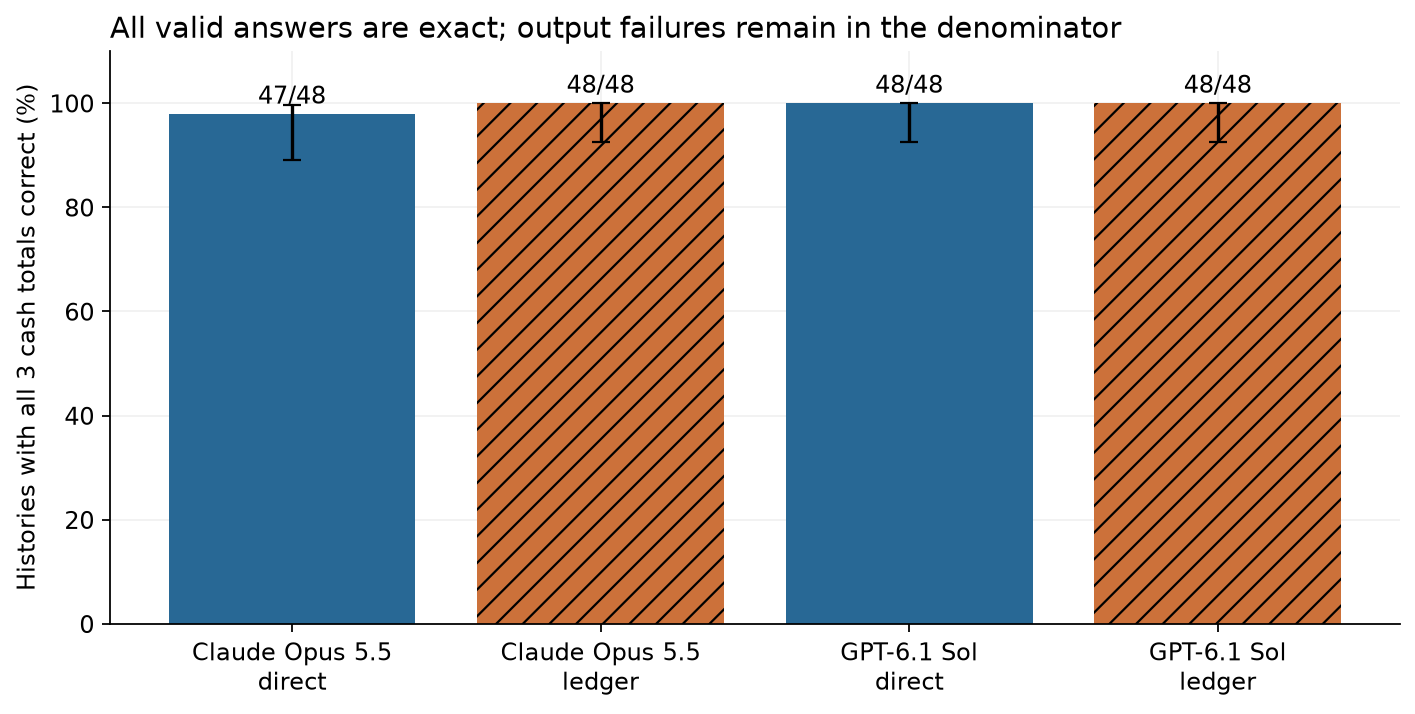

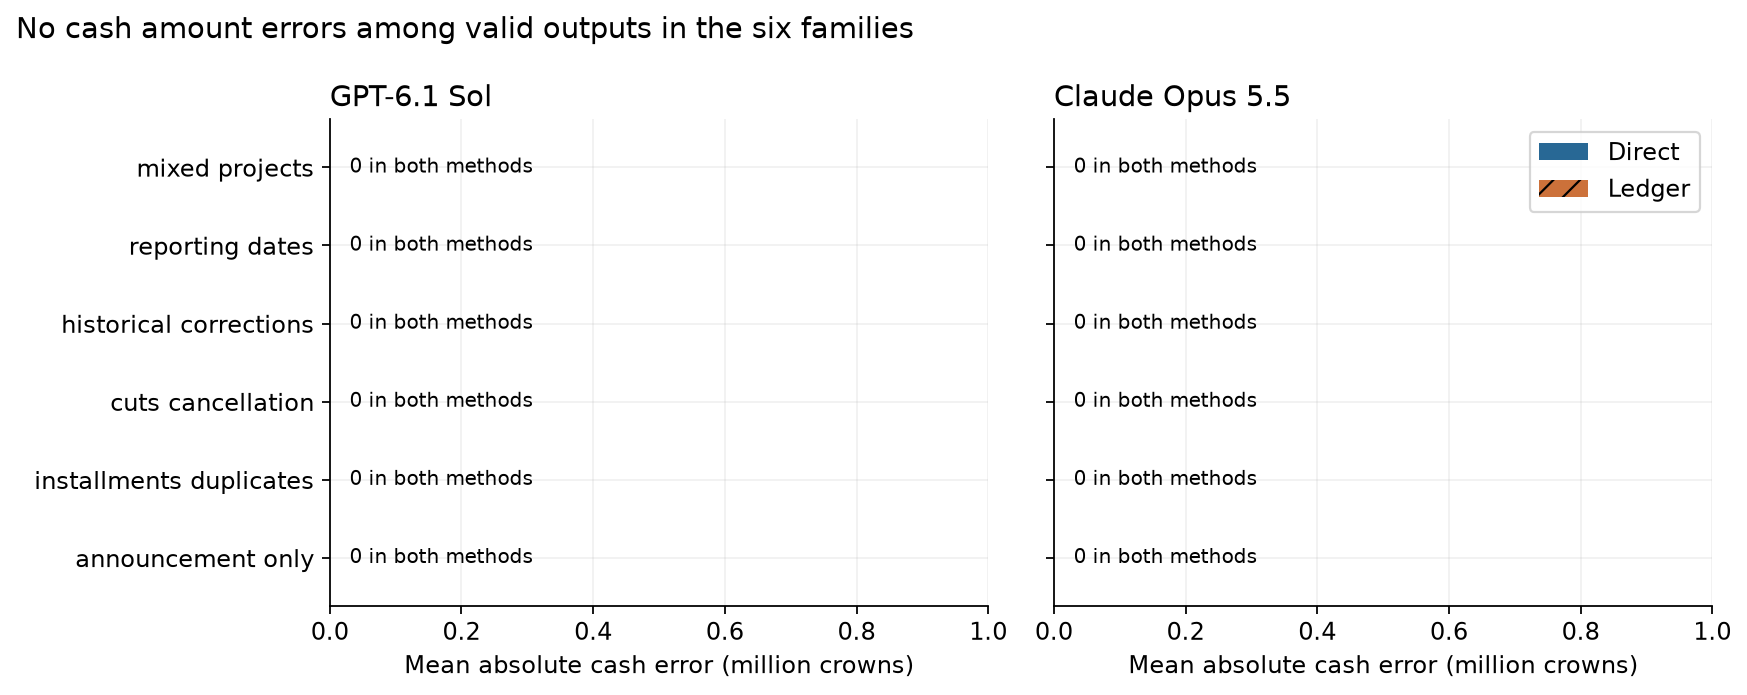

In [5]:
HMAP={h['history_id']:h for h in HISTORIES}
def scored(rows):
    out=[]; qs=[]
    for r in rows:
        h=HMAP[r['history_id']]; z={k:v for k,v in r.items() if k not in ('prediction','events')}
        z.update(cash_exact=False,authority_exact=False,status_exact=False,cash_mae=None,cash_over=None)
        if r['valid']:
            e=[abs(p['cash_paid']-g['cash_paid']) for p,g in zip(r['prediction'],h['gold'])]
            z.update(cash_exact=all(x<1e-8 for x in e),cash_mae=float(np.mean(e)),
                     cash_over=float(np.mean([max(0,p['cash_paid']-g['cash_paid']) for p,g in zip(r['prediction'],h['gold'])])),
                     authority_exact=all(abs(p['active_authority']-g['active_authority'])<1e-8 for p,g in zip(r['prediction'],h['gold'])),
                     status_exact=all(p['status']==g['status'] for p,g in zip(r['prediction'],h['gold'])))
            for p,g in zip(r['prediction'],h['gold']):
                qs.append(dict(history_id=r['history_id'],family=r['family'],model=r['model'],method=r['method'],
                    quarter_end=p['quarter_end'],pred_cash=p['cash_paid'],gold_cash=g['cash_paid'],
                    false_cash=g['cash_paid']==0 and p['cash_paid']>0,error=p['cash_paid']-g['cash_paid']))
        if r['valid'] and r['method']=='ledger':
            fields=['source_id','event_id','kind','effective_date','amount']
            def tuples(ev): return {tuple(e[k] for k in fields) for e in ev}
            target=tuples([e for e in h['gold_events'] if e['source_id'] in {d['document_id'] for d in visible_docs(h)}])
            got=tuples(r['events']); z.update(event_tp=len(target&got),event_pred=len(got),event_gold=len(target))
        out.append(z)
    return pd.DataFrame(out),pd.DataFrame(qs)
scores,quarters=scored(test_rows); dev_scores,_=scored(dev_rows)
def wilson(k,n):
    z=1.96; p=k/n; den=1+z*z/n; mid=(p+z*z/(2*n))/den; half=z*math.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return [mid-half,mid+half]
summary=[]
for (m,t),g in scores.groupby(['model','method'],sort=False):
    n=len(g); correct=int(g.cash_exact.sum()); low,high=wilson(correct,n)
    sub=quarters[(quarters.model==m)&(quarters.method==t)]
    summary.append(dict(model=m,method=t,histories=n,valid=int(g.valid.sum()),cash_exact=correct,exact_low=low,exact_high=high,
       cash_mae=float(g.cash_mae.mean()),mean_overstatement=float(g.cash_over.mean()),authority_exact=int(g.authority_exact.sum()),
       status_exact=int(g.status_exact.sum()),false_cash_quarters=int(sub.false_cash.sum()),zero_cash_quarters=int((sub.gold_cash==0).sum()),
       median_latency_s=float(g.latency_s.median()),claude_list_usd=float(g.list_cost_usd.sum()) if m.startswith('Claude') else None))
summary=pd.DataFrame(summary); display(summary)
contrasts=[]; rng=np.random.default_rng(SEED)
for model in MODELS:
    p=scores[scores.model==model].pivot(index='history_id',columns='method',values='cash_mae').dropna()
    diff=(p.ledger-p.direct).to_numpy(); boots=np.mean(diff[rng.integers(0,len(diff),(5000,len(diff)))],axis=1)
    contrasts.append(dict(model=model,paired_histories=len(diff),ledger_minus_direct=float(diff.mean()),low=float(np.quantile(boots,.025)),high=float(np.quantile(boots,.975))))
contrasts=pd.DataFrame(contrasts); display(contrasts)
scores.to_csv(OUT/'history_scores.csv',index=False); quarters.to_csv(OUT/'quarter_scores.csv',index=False)
summary.to_csv(OUT/'summary.csv',index=False); contrasts.to_csv(OUT/'paired_contrasts.csv',index=False)
dev_scores.to_csv(OUT/'development_scores.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4.6))
labels=[]; values=[]; lows=[]; highs=[]
for _,r in summary.iterrows():
    labels.append(r['model']+'\n'+r['method']); values.append(r.cash_exact/r.histories*100)
    lows.append(max(0,(r.cash_exact/r.histories-r.exact_low)*100)); highs.append(max(0,(r.exact_high-r.cash_exact/r.histories)*100))
ax.bar(range(len(labels)),values,color=['#286895','#cc713a','#286895','#cc713a'],hatch=['','//','','//'])
ax.errorbar(range(len(labels)),values,yerr=[lows,highs],fmt='none',ecolor='black',capsize=4)
ax.set_xticks(range(len(labels)),labels); ax.set_ylabel('Histories with all 3 cash totals correct (%)'); ax.set_ylim(0,110)
ax.set_title('All valid answers are exact; output failures remain in the denominator')
for i,(_,r) in enumerate(summary.iterrows()): ax.text(i,values[i]+2,f'{int(r.cash_exact)}/{int(r.histories)}',ha='center')
fig.tight_layout(); fig.savefig(FIG/'cash_exact.png'); display(Image(filename=str(FIG/'cash_exact.png'), alt='Exact cash histories: Claude Opus 5.5 direct passes 47 of 48 because one answer has a prose prefix; its ledger and both GPT-6.1 Sol methods pass 48 of 48. Error bars are 95 percent Wilson intervals.')); plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(11,4.4),sharey=True)
for ax,model in zip(axes,MODELS):
    sub=scores[scores.model==model].groupby(['family','method']).cash_mae.mean().unstack().reindex(FAMILIES)
    x=np.arange(len(sub)); ax.barh(x-.17,sub.direct,height=.32,label='Direct',color='#286895')
    ax.barh(x+.17,sub.ledger,height=.32,label='Ledger',color='#cc713a',hatch='//')
    ax.set_xlim(0,max(1,float(sub.max().max())*1.25)); ax.set_yticks(x,[f.replace('_',' ') for f in sub.index]); ax.set_xlabel('Mean absolute cash error (million crowns)'); ax.set_title(model)

    for yi in x:
        if float(sub.iloc[yi].max())==0: ax.text(.03,yi,'0 in both methods',va='center',fontsize=9)
axes[1].legend(); fig.suptitle('No cash amount errors among valid outputs in the six families',x=.01,ha='left'); fig.tight_layout()
fig.savefig(FIG/'cash_error_by_family.png'); display(Image(filename=str(FIG/'cash_error_by_family.png'), alt='Both models and both methods have zero cash amount error among valid outputs across six fiscal history families. Each family contains eight held-out histories.')); plt.close(fig)

### What the measured differences support

GPT-6.1 Sol: direct 48/48 and ledger 48/48 exact cash histories; Claude Opus 5.5: direct 47/48 and ledger 48/48 exact cash histories. All 191 schema-valid held-out answers have zero cash error. There is 1 invalid output among 192 held-out responses. The invalid answer contains the correct cash, authority and status values but begins with prose. The sample contains explicit synthetic records and only six recurring history structures; it does not establish equal performance on public fiscal documents.

| Model | Method | Exact cash histories | Valid responses | Cash MAE, valid only | Authority exact | Status exact |
| --- | --- | --- | --- | --- | --- | --- |
| Claude Opus 5.5 | direct | 47/48 | 47/48 | 0.000 | 47/48 | 47/48 |
| Claude Opus 5.5 | ledger | 48/48 | 48/48 | 0.000 | 48/48 | 48/48 |
| GPT-6.1 Sol | direct | 48/48 | 48/48 | 0.000 | 48/48 | 48/48 |
| GPT-6.1 Sol | ledger | 48/48 | 48/48 | 0.000 | 48/48 | 48/48 |

The exact-history columns use all 48 histories for each method. MAE means mean absolute cash error, measured in million crowns; it uses only the valid responses shown beside it. Authority and status also require all three quarters to match. An invalid output fails each exact-history column, even if a reader can see a plausible answer in the raw response.

For GPT-6.1 Sol, ledger minus direct cash error is 0.000 million crowns, with a 95% paired history-bootstrap interval [0.000, 0.000] on 48 histories with valid answers in both arms. For Claude Opus 5.5, ledger minus direct cash error is 0.000 million crowns, with a 95% paired history-bootstrap interval [0.000, 0.000] on 47 histories with valid answers in both arms. These intervals describe the observed valid-pair sample. An interval of [0, 0] when all observed errors are zero is not proof that the methods are equivalent on unseen cases. The Wilson bars in the first figure remain below 100% at their lower end even when all 48 histories pass.

The first figure compares each method within its model. Bar heights count complete three-quarter cash histories; the black lines are 95% Wilson intervals over histories. The second figure groups the 48 histories into six families of eight. Its horizontal axis is absolute cash error in million crowns, so a zero bar means that no cash discrepancy was observed among valid answers in that family. It does not imply that every response met the output contract.

There are 0 false positive cash quarters among 96 valid zero-cash quarter outputs. These quarters are nested within the eight no-payment histories and model-method runs; they are not 96 independent economic cases.

The ledger responses match 672 of 672 gold source-event records and contain 672 records. Event precision is 1.000, the share of extracted records that exactly match gold. Recall is 1.000, the share of gold records found. The comparison checks source ID, reference, kind, date and amount. A duplicate report can be unnecessary for a correct cash total and still matter to this strict event audit.

GPT-6.1 Sol median CLI latency is 5.6 seconds direct and 8.1 seconds for the ledger. Claude Opus 5.5 median CLI latency is 4.0 seconds direct and 5.6 seconds for the ledger. The timings include CLI startup and service variation. They come from this run, without randomized execution order or repeated timing trials, and should not be interpreted as stable model-speed rankings.


### Formatting diagnostic

This secondary analysis was added after inspecting output-format failures. It extracts one JSON payload exactly as returned, without changing amounts or making another model call. A prose prefix or enclosing fence is ignored only in this diagnostic. It is not part of the frozen primary score. A recovered payload does not change the failure count above.

In [6]:

# Secondary diagnostic only. The primary scores above remain unchanged.
# Extract one JSON payload verbatim, without new model calls or editing values.
format_diagnostics=[]
for r in test_rows:
    d=dict(history_id=r['history_id'],model=r['model'],method=r['method'],primary_valid=r['valid'],
           unchanged_json_payload_recoverable=False,recovered_cash_exact=None,recovered_all_fields_exact=None)
    if not r['valid']:
        raw=CACHE[r['cache_key']]['response']['text']
        try:
            start=raw.index('{')
            obj,end=json.JSONDecoder().raw_decode(raw[start:])
            assert raw[start+end:].strip() in ('','```'), 'Multiple or trailing payloads'
            pred=validate_quarters(obj['quarters']) if r['method']=='direct' else validate_quarters(reconcile(obj['events'],HMAP[r['history_id']]))
            d['unchanged_json_payload_recoverable']=True
            d['payload_start']=start; d['payload_length']=end
            d['recovered_cash_exact']=all(abs(p['cash_paid']-g['cash_paid'])<1e-8 for p,g in zip(pred,HMAP[r['history_id']]['gold']))
            d['recovered_all_fields_exact']=pred==HMAP[r['history_id']]['gold']
        except Exception: pass
    format_diagnostics.append(d)
format_diagnostics=pd.DataFrame(format_diagnostics)
format_diagnostics.to_csv(OUT/'format_diagnostics.csv',index=False)
display(format_diagnostics[~format_diagnostics.primary_valid])
print('Primary exactness unchanged. This diagnostic is post hoc and has no model calls.')


,history_id,model,method,primary_valid,unchanged_json_payload_recoverable,recovered_cash_exact,recovered_all_fields_exact,payload_start,payload_length
16,TEST-005,Claude Opus 5.5,direct,False,True,True,True,104.0,284.0


Primary exactness unchanged. This diagnostic is post hoc and has no model calls.


## 6. Worked cases and error analysis

The examples below are selected deterministically: one typical installment history, one cancellation, one correction, one reporting-date case and one mixed-project case. If any held-out answers fail, the largest observed cash error is shown as an additional case. This avoids choosing examples by how persuasive they sound. Every case links through its stable history ID to the fixtures and through a cache key to the exact raw response.

Read the source excerpt first, then compare true and returned quarter totals. A correction may change Q1 even though its document was published in Q3: all three totals use the September as-of information set. This is intended. A zero-error result on these cases would not establish accuracy on real public data.

### TEST-002: installments duplicates

,document_id,published_on,text
0,TEST-002-D01,2026-01-10,A proposed funding announcement on 2026-01-09 of 152 million crowns for TEST-002 River Clinic. No approval...
1,TEST-002-D02,2026-02-06,"Effective 2026-02-01, total active spending authority for TEST-002 River Clinic becomes 112 million crowns..."
2,TEST-002-D03,2026-02-20,Contract for TEST-002 River Clinic valued at 49 million crowns signed on 2026-02-19 is currently unpaid. T...
3,TEST-002-D04,2026-03-21,A settled external cash transfer of 19 million crowns for TEST-002 River Clinic with payment reference TES...
4,TEST-002-D05,2026-06-18,External cash transfer of 30 million crowns for TEST-002 River Clinic settled on 2026-06-15 under referenc...
5,TEST-002-D06,2026-06-25,A settled external cash transfer of 19 million crowns for TEST-002 River Clinic with payment reference TES...
6,TEST-002-D07,2026-07-03,Checkpoint TEST-002-C1 reports cumulative cash paid for TEST-002 River Clinic through 2026-06-30 as 49 mil...
7,TEST-002-D08,2026-09-11,A settled external cash transfer of 13 million crowns for TEST-002 River Clinic with payment reference TES...


,quarter_end,gold_cash,active_authority,status,Claude Opus 5.5 direct,Claude Opus 5.5 ledger,GPT-6.1 Sol direct,GPT-6.1 Sol ledger
0,2026-03-31,19,112,partly_paid,19,19,19,19
1,2026-06-30,49,112,partly_paid,49,49,49,49
2,2026-09-30,62,112,partly_paid,62,62,62,62


### TEST-003: cuts cancellation

,document_id,published_on,text
0,TEST-003-D01,2026-01-10,A proposed funding announcement on 2026-01-09 of 156 million crowns for TEST-003 River Clinic. No approval...
1,TEST-003-D02,2026-02-06,"Effective 2026-02-01, total active spending authority for TEST-003 River Clinic becomes 116 million crowns..."
2,TEST-003-D03,2026-02-20,Contract for TEST-003 River Clinic valued at 58 million crowns signed on 2026-02-19 is currently unpaid. T...
3,TEST-003-D04,2026-03-21,A settled external cash transfer of 32 million crowns for TEST-003 River Clinic with payment reference TES...
4,TEST-003-D08,2026-05-14,Total active spending authority for TEST-003 River Clinic is cut to 68 million crowns effective 2026-05-12...
5,TEST-003-D05,2026-06-18,A settled external cash transfer of 26 million crowns for TEST-003 River Clinic with payment reference TES...
6,TEST-003-D06,2026-06-25,External cash transfer of 32 million crowns for TEST-003 River Clinic settled on 2026-03-18 under referenc...
7,TEST-003-D07,2026-07-03,Checkpoint TEST-003-C1 reports cumulative cash paid for TEST-003 River Clinic through 2026-06-30 as 58 mil...
8,TEST-003-D09,2026-08-21,From 2026-08-20 the TEST-003 River Clinic is cancelled and active spending authority is zero. Earlier cash...
9,TEST-003-D10,2026-09-12,A cash payment for TEST-003 River Clinic of 8 million crowns is proposed for 2026-09-20 but has not settle...


...

,document_id,published_on,text
0,TEST-006-D01,2026-01-10,A proposed funding announcement on 2026-01-09 of 162 million crowns for TEST-006 River Clinic. No approval...
1,TEST-006-D02,2026-02-06,"As of 2026-02-01, the total active spending authority for TEST-006 River Clinic is set at 122 million crow..."
2,TEST-006-D03,2026-02-20,"A contract for TEST-006 River Clinic worth 43 million crowns was signed on 2026-02-19, but it remains enti..."
3,TEST-006-D04,2026-03-21,A settled external cash transfer of 24 million crowns for TEST-006 River Clinic with payment reference TES...
4,TEST-006-D05,2026-06-18,A joint settlement on 2026-06-15 paid 60 million crowns: 19 for TEST-006 River Clinic under reference TEST...
5,TEST-006-D06,2026-06-25,A settled external cash transfer of 24 million crowns for TEST-006 River Clinic with payment reference TES...
6,TEST-006-D07,2026-07-03,"Through 2026-06-30, checkpoint TEST-006-C1 indicates cumulative cash paid for TEST-006 River Clinic totals..."
7,TEST-006-D09,2026-08-16,External cash transfer of 99 million crowns for TEST-006 River Water settled on 2026-08-15 under reference...
8,TEST-006-D08,2026-09-11,A settled external cash transfer of 29 million crowns for TEST-006 River Clinic with payment reference TES...
9,TEST-006-D10,2026-09-20,Checkpoint TEST-006-C2 reports cumulative cash paid for TEST-006 River Clinic through 2026-09-15 as 72 mil...


,quarter_end,gold_cash,active_authority,status,Claude Opus 5.5 direct,Claude Opus 5.5 ledger,GPT-6.1 Sol direct,GPT-6.1 Sol ledger
0,2026-03-31,24,122,partly_paid,24,24,24,24
1,2026-06-30,43,122,partly_paid,43,43,43,43
2,2026-09-30,72,122,partly_paid,72,72,72,72


### Raw response and parsed events for TEST-004

Cache key: d07e7cf288babbf95765ea4ca14595bbea2ba27a573989b4e84690a5127eb7ed
{"events":[{"source_id":"TEST-004-D01","event_id":"TEST-004-D01","kind":"announcement","effective_date":"2026-01-09","amount":147},{"source_id":"TEST-004-D02","event_id":"TEST-004-D02","kind":"authority","effective_date":"2026-02-01","amount":107},{"source_id":"TEST-004-D04","event_id":"TEST-004-P1","kind":"payment","effective_date":"2026-03-18","amount":25},{"source_id":"TEST-004-D05","event_id":"TEST-004-P2","kind":"payment","effective_date":"2026-06-15","amount":26},{"source_id":"TEST-004-D06","event_id":"TEST-004-P1","kind":"payment","effective_date":"2026-03-18","amount":25},{"source_id":"TEST-004-D07","event_id":"TEST-004-C1","kind":"cumulative","effective_date":"2026-06-30","amount":51},{"source_id":"TEST-004-D08","event_id":"TEST-004-P1","kind":"payment","effective_date":"2026-03-18","amount":21},{"source_id":"TEST-004-D09","event_id":"TEST-004-C1","kind":"cumulative","effective_date":"2026-06-30","amou

,source_id,event_id,kind,effective_date,amount
0,TEST-004-D01,TEST-004-D01,announcement,2026-01-09,147
1,TEST-004-D02,TEST-004-D02,authority,2026-02-01,107
2,TEST-004-D04,TEST-004-P1,payment,2026-03-18,25
3,TEST-004-D05,TEST-004-P2,payment,2026-06-15,26
4,TEST-004-D06,TEST-004-P1,payment,2026-03-18,25
5,TEST-004-D07,TEST-004-C1,cumulative,2026-06-30,51
6,TEST-004-D08,TEST-004-P1,payment,2026-03-18,21
7,TEST-004-D09,TEST-004-C1,cumulative,2026-06-30,47
8,TEST-004-D10,TEST-004-P3,payment,2026-09-09,10


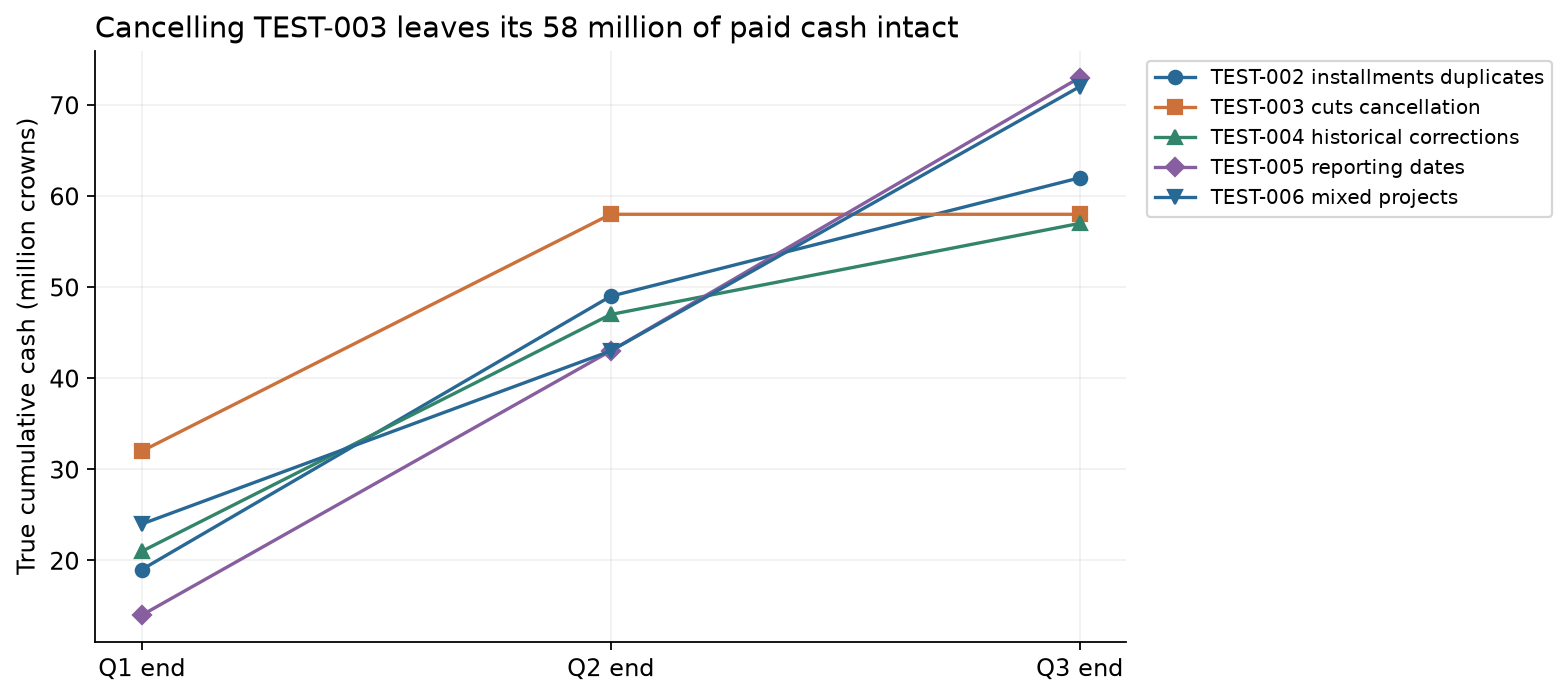

In [7]:
example_ids=[]
for family in ['installments_duplicates','cuts_cancellation','historical_corrections','reporting_dates','mixed_projects']:
    candidates=[h for h in test if h['family']==family]
    if candidates: example_ids.append(candidates[0]['history_id'])
bad=scores[scores.cash_mae.fillna(-1)>0].sort_values('cash_mae',ascending=False)
if len(bad) and bad.iloc[0].history_id not in example_ids: example_ids.append(bad.iloc[0].history_id)
for hid in example_ids:
    h=HMAP[hid]; display(Markdown('### '+hid+': '+h['family'].replace('_',' ')))
    display(pd.DataFrame(visible_docs(h))[['document_id','published_on','text']])
    comparison=pd.DataFrame(h['gold']).rename(columns={'cash_paid':'gold_cash'})
    for r in test_rows:
        if r['history_id']==hid:
            comparison[r['model']+' '+r['method']]=[p['cash_paid'] for p in r['prediction']] if r['valid'] else [None]*3
    display(comparison)
chosen=example_ids[2] if len(example_ids)>2 else test[0]['history_id']
selected=next(r for r in test_rows if r['history_id']==chosen and r['model']=='GPT-6.1 Sol' and r['method']=='ledger')
display(Markdown('### Raw response and parsed events for '+chosen))
print('Cache key:',selected['cache_key']); print(CACHE[selected['cache_key']]['response']['text'])
if selected['valid']: display(pd.DataFrame(selected['events']))
fig,ax=plt.subplots(figsize=(10,4.5))
for hidx,hid in enumerate(example_ids[:5]):
    h=HMAP[hid]; true=np.array([x['cash_paid'] for x in h['gold']]); ax.plot([1,2,3],true,marker=['o','s','^','D','v'][hidx],label=hid+' '+h['family'].replace('_',' '))
ax.set_xticks([1,2,3],['Q1 end','Q2 end','Q3 end']); ax.set_ylabel('True cumulative cash (million crowns)')
cancel_cash=HMAP['TEST-003']['gold'][-1]['cash_paid']
ax.set_title(f'Cancelling TEST-003 leaves its {cancel_cash} million of paid cash intact'); ax.legend(fontsize=9,loc='upper left',bbox_to_anchor=(1.01,1))
fig.tight_layout(); fig.savefig(FIG/'example_cash_paths.png'); display(Image(filename=str(FIG/'example_cash_paths.png'), alt='Gold cash paths for five examples. TEST-003 rises from 32 to 58 million crowns and stays at 58 after cancellation, while the other displayed histories receive a third-quarter payment.')); plt.close(fig)
dump(OUT/'worked_example_ids.json',example_ids)

### TEST-001: Approval and contracts still imply zero cash

> TEST-001-D02 (published 2026-02-06): Effective 2026-02-01, total active spending authority for TEST-001 River Clinic becomes 126 million crowns. This is a total ceiling, not an increment or a cash payment.

> TEST-001-D03 (published 2026-02-20): Contract for TEST-001 River Clinic valued at 62 million crowns signed on 2026-02-19 is currently unpaid. This action does not alter existing budget authority.

> TEST-001-D07 (published 2026-09-18): A cash payment for TEST-001 River Clinic of 14 million crowns is proposed for 2026-10-07 but has not settled. Do not describe it as money already paid.

> TEST-001-D08 (published 2026-09-19): External cash transfer of 55 million crowns for TEST-001 River Water settled on 2026-09-18 under reference TEST-001-W1. Note that reporting may occur later.

The authority is 126 million crowns, but the target has no settled transfer. A signed contract and an unsettled proposal do not change this. A separate water-programme payment must also be ignored. The expected cash path is 0, 0, 0. This family contains eight held-out histories.

| Model | Method | Returned Q1, Q2, Q3 cash | Returned active authority |
| --- | --- | --- | --- |
| GPT-6.1 Sol | direct | 0, 0, 0 | 126, 126, 126 |
| GPT-6.1 Sol | ledger | 0, 0, 0 | 126, 126, 126 |
| Claude Opus 5.5 | direct | 0, 0, 0 | 126, 126, 126 |
| Claude Opus 5.5 | ledger | 0, 0, 0 | 126, 126, 126 |

4/4 model-method answers reproduce the cash path 0, 0, 0 exactly under the strict output contract. Across the eight histories in this family, 32/32 model-method answers are exact. These are four model-method answers to the same case, not four independent economic observations. The fixtures and gold are stored under `TEST-001` in `data/histories.json`.


### TEST-002: A repeated transfer is not another payment

> TEST-002-D04 (published 2026-03-21): A settled external cash transfer of 19 million crowns for TEST-002 River Clinic with payment reference TEST-002-P1 and settlement date 2026-03-18. Reporting may occur later.

> TEST-002-D05 (published 2026-06-18): External cash transfer of 30 million crowns for TEST-002 River Clinic settled on 2026-06-15 under reference TEST-002-P2. Note that reporting may occur later.

> TEST-002-D06 (published 2026-06-25): A settled external cash transfer of 19 million crowns for TEST-002 River Clinic with payment reference TEST-002-P1 and settlement date 2026-03-18. Reporting may occur later.

> TEST-002-D07 (published 2026-07-03): Checkpoint TEST-002-C1 reports cumulative cash paid for TEST-002 River Clinic through 2026-06-30 as 49 million crowns. Includes all earlier payments; not an additional transfer.

> TEST-002-D08 (published 2026-09-11): A settled external cash transfer of 13 million crowns for TEST-002 River Clinic with payment reference TEST-002-P3 and settlement date 2026-09-09. Reporting may occur later.

Transfer P1 paid 19 in March. The June document repeats P1 instead of making a second payment. P2 adds 30, and the cumulative June checkpoint confirms 49; it is not another 49 of spending. P3 adds 13, giving 19, 49, 62. Counting P1 twice would overstate Q1 onward. There are eight installment histories.

| Model | Method | Returned Q1, Q2, Q3 cash | Returned active authority |
| --- | --- | --- | --- |
| GPT-6.1 Sol | direct | 19, 49, 62 | 112, 112, 112 |
| GPT-6.1 Sol | ledger | 19, 49, 62 | 112, 112, 112 |
| Claude Opus 5.5 | direct | 19, 49, 62 | 112, 112, 112 |
| Claude Opus 5.5 | ledger | 19, 49, 62 | 112, 112, 112 |

4/4 model-method answers reproduce the cash path 19, 49, 62 exactly under the strict output contract. Across the eight histories in this family, 32/32 model-method answers are exact. These are four model-method answers to the same case, not four independent economic observations. The fixtures and gold are stored under `TEST-002` in `data/histories.json`.


### TEST-003: Cancellation retains money already paid

> TEST-003-D04 (published 2026-03-21): A settled external cash transfer of 32 million crowns for TEST-003 River Clinic with payment reference TEST-003-P1 and settlement date 2026-03-18. Reporting may occur later.

> TEST-003-D08 (published 2026-05-14): Total active spending authority for TEST-003 River Clinic is cut to 68 million crowns effective 2026-05-12. No refunds are issued for earlier payments. This is not a cash transfer.

> TEST-003-D05 (published 2026-06-18): A settled external cash transfer of 26 million crowns for TEST-003 River Clinic with payment reference TEST-003-P2 and settlement date 2026-06-15. Reporting may occur later.

> TEST-003-D09 (published 2026-08-21): From 2026-08-20 the TEST-003 River Clinic is cancelled and active spending authority is zero. Earlier cash payments are retained by recipients, without refund.

> TEST-003-D10 (published 2026-09-12): A cash payment for TEST-003 River Clinic of 8 million crowns is proposed for 2026-09-20 but has not settled. Do not describe it as money already paid.

March cash of 32 and June cash of 26 remain paid after the August cancellation. The correct cash path is 32, 58, 58; active authority follows 116, 68, 0. A rule that replaces cash with the latest budget amount would erase 58 million actually paid. Eight test histories use this structure.

| Model | Method | Returned Q1, Q2, Q3 cash | Returned active authority |
| --- | --- | --- | --- |
| GPT-6.1 Sol | direct | 32, 58, 58 | 116, 68, 0 |
| GPT-6.1 Sol | ledger | 32, 58, 58 | 116, 68, 0 |
| Claude Opus 5.5 | direct | 32, 58, 58 | 116, 68, 0 |
| Claude Opus 5.5 | ledger | 32, 58, 58 | 116, 68, 0 |

4/4 model-method answers reproduce the cash path 32, 58, 58 exactly under the strict output contract. Across the eight histories in this family, 32/32 model-method answers are exact. These are four model-method answers to the same case, not four independent economic observations. The fixtures and gold are stored under `TEST-003` in `data/histories.json`.


### TEST-004: A correction changes an earlier quarter

> TEST-004-D04 (published 2026-03-21): External cash transfer of 25 million crowns for TEST-004 River Clinic settled on 2026-03-18 under reference TEST-004-P1. Note that reporting may occur later.

> TEST-004-D07 (published 2026-07-03): Through 2026-06-30, checkpoint TEST-004-C1 indicates cumulative cash paid for TEST-004 River Clinic totals 51 million crowns. This includes prior payments and is not an additional transfer.

> TEST-004-D08 (published 2026-07-22): Payment reference TEST-004-P1 for TEST-004 River Clinic settled on 2026-03-18 is corrected to 21 million crowns via accounting adjustment. This is not a new transfer or refund.

> TEST-004-D09 (published 2026-07-23): Corrected checkpoint TEST-004-C1 replaces its earlier cumulative cash total for TEST-004 River Clinic through 2026-06-30 with 47 million crowns. Not new spending.

> TEST-004-D10 (published 2026-09-11): External cash transfer of 10 million crowns for TEST-004 River Clinic settled on 2026-09-09 under reference TEST-004-P3. Note that reporting may occur later.

P1 was first reported as 25 but corrected in July to 21. The June cumulative checkpoint was also corrected to 47. At the September as-of date, the corrected path is 21, 47, 57. The ledger replaces P1 and the checkpoint by their shared references. For a prediction equal to this path, absolute error is (0 + 0 + 0) / 3 = 0. These are revised estimates of past quarters, not the estimates available in March. All eight correction histories explicitly update both payment and checkpoint; stale checkpoint conflicts are untested.

| Model | Method | Returned Q1, Q2, Q3 cash | Returned active authority |
| --- | --- | --- | --- |
| GPT-6.1 Sol | direct | 21, 47, 57 | 107, 107, 107 |
| GPT-6.1 Sol | ledger | 21, 47, 57 | 107, 107, 107 |
| Claude Opus 5.5 | direct | 21, 47, 57 | 107, 107, 107 |
| Claude Opus 5.5 | ledger | 21, 47, 57 | 107, 107, 107 |

4/4 model-method answers reproduce the cash path 21, 47, 57 exactly under the strict output contract. Across the eight histories in this family, 32/32 model-method answers are exact. These are four model-method answers to the same case, not four independent economic observations. The fixtures and gold are stored under `TEST-004` in `data/histories.json`.


### TEST-005: Publication date differs from settlement date

> TEST-005-D10 (published 2026-03-15): A cash payment for TEST-005 River Clinic of 17 million crowns is proposed for 2026-04-10 but has not settled. Do not describe it as money already paid.

> TEST-005-D06 (published 2026-06-25): External cash transfer of 14 million crowns for TEST-005 River Clinic settled on 2026-03-18 under reference TEST-005-P1. Note that reporting may occur later.

> TEST-005-D04 (published 2026-07-08): External cash transfer of 14 million crowns for TEST-005 River Clinic settled on 2026-03-18 under reference TEST-005-P1. Note that reporting may occur later.

> TEST-005-D09 (published 2026-09-15): Effective 2026-10-01, total active spending authority for TEST-005 River Clinic becomes 148 million crowns. This is a total ceiling, not an increment or a cash payment.

The source published in July describes a March settlement of 14. It belongs in reconstructed Q1 cash. A September authorization effective on 1 October does not change Q3 authority, which stays 123. Assigning amounts by publication date would instead shift cash between quarters. Eight histories contain this reporting-date structure.

| Model | Method | Returned Q1, Q2, Q3 cash | Returned active authority |
| --- | --- | --- | --- |
| GPT-6.1 Sol | direct | 14, 43, 73 | 123, 123, 123 |
| GPT-6.1 Sol | ledger | 14, 43, 73 | 123, 123, 123 |
| Claude Opus 5.5 | direct | INVALID | INVALID |
| Claude Opus 5.5 | ledger | 14, 43, 73 | 123, 123, 123 |

3/4 model-method answers reproduce the cash path 14, 43, 73 exactly under the strict output contract. Across the eight histories in this family, 31/32 model-method answers are exact. These are four model-method answers to the same case, not four independent economic observations. The fixtures and gold are stored under `TEST-005` in `data/histories.json`.


### TEST-006: A combined notice contains two programmes

> TEST-006-D05 (published 2026-06-18): A joint settlement on 2026-06-15 paid 60 million crowns: 19 for TEST-006 River Clinic under reference TEST-006-P2 and 41 for TEST-006 River Water. The project amount is only its own share.

> TEST-006-D09 (published 2026-08-16): External cash transfer of 99 million crowns for TEST-006 River Water settled on 2026-08-15 under reference TEST-006-W2. Note that reporting may occur later.

> TEST-006-D10 (published 2026-09-20): Checkpoint TEST-006-C2 reports cumulative cash paid for TEST-006 River Clinic through 2026-09-15 as 72 million crowns. Includes all earlier payments; not an additional transfer.

The joint settlement contains 19 for the clinic and 41 for the water programme, a total of 60. Only the clinic share counts. A later 99-million water payment also stays outside the target. Correct clinic cash is 24, 43, 72. Eight mixed-project histories test this separation.

| Model | Method | Returned Q1, Q2, Q3 cash | Returned active authority |
| --- | --- | --- | --- |
| GPT-6.1 Sol | direct | 24, 43, 72 | 122, 122, 122 |
| GPT-6.1 Sol | ledger | 24, 43, 72 | 122, 122, 122 |
| Claude Opus 5.5 | direct | 24, 43, 72 | 122, 122, 122 |
| Claude Opus 5.5 | ledger | 24, 43, 72 | 122, 122, 122 |

4/4 model-method answers reproduce the cash path 24, 43, 72 exactly under the strict output contract. Across the eight histories in this family, 32/32 model-method answers are exact. These are four model-method answers to the same case, not four independent economic observations. The fixtures and gold are stored under `TEST-006` in `data/histories.json`.


### Observed output failures

The following held-out responses fail the primary output contract. They remain failures in the headline denominator. A reader can distinguish a formatting issue from a cash-amount issue by inspecting the exact text.

#### TEST-005, Claude Opus 5.5, direct

Parser result: `JSONDecodeError: Expecting value: line 1 column 1 (char 0)`. Cache key: `20d28b9ab035986a05fb5f5680d41992741573fad040c42aaf9a228fecd766fd`.

```text
Q1: P1 14. Q2: 14+29=43 (checkpoint consistent). Q3: 73. Authority 123 throughout (148 effective Oct).

{"quarters":[{"quarter_end":"2026-03-31","cash_paid":14,"active_authority":123,"status":"partly_paid"},{"quarter_end":"2026-06-30","cash_paid":43,"active_authority":123,"status":"partly_paid"},{"quarter_end":"2026-09-30","cash_paid":73,"active_authority":123,"status":"partly_paid"}]}
```



The cash-path figure plots the gold trajectories for five displayed examples. Its horizontal axis is quarter-end; the vertical axis is cumulative paid cash in million crowns. TEST-003 stays at 58 million in Q2 and Q3 even though its authority falls from 68 to zero. The lines describe the generated facts, not model predictions. Different event structures can lead to the same monotone cash pattern, so accurate totals alone cannot tell us whether every source event was extracted correctly.

## 7. Limits and practical use

These cases test accounting definitions and chronology under controlled language. They do not represent countries, languages, missing records or uncertain accounting conventions. Templates and family structures recur, so the effective variety is smaller than 48 unrelated public policy histories. No claim about fiscal multipliers, macroeconomic stimulus or causal identification follows from these measurements.

An event ledger makes intermediate mistakes inspectable. It also adds places to fail: a wrong reference or effective date can survive flawless arithmetic. A cumulative checkpoint can hide an earlier extraction omission when the final totals happen to be correct. We therefore report event matching separately from cash accuracy. That matching is strict about source records and is not a complete semantic judgment.

Both methods have exactly the same evidence and one call per model-history. They do not have identical token budgets because a ledger can be longer. Model releases, reasoning effort, template wording and higher document counts could change the comparison. The paired sample supports a workflow comparison on these fixtures; a real deployment still needs public-document validation and an explicit policy for contradictory or unknown facts.

Every historical payment correction is accompanied by an updated cumulative checkpoint. The reducer would otherwise trust the stale checkpoint for cash before that checkpoint date. This experiment does not establish that a ledger handles such conflicts. All histories have approved authority by Q1, so an announced-only final state and ambiguity about approval are also outside the tested coverage.

The source templates explicitly label unsettled commitments and repeated checkpoints. Their clarity helps both methods. If all valid answers have zero cash error, the useful result is that this level of difficulty does not justify an accuracy claim for the extra ledger machinery. A ledger may still be useful for inspection, but that benefit has not been measured with human reviewers here.


## 8. Reproduction and spend

Run this notebook from its own directory with Python, pandas, NumPy, matplotlib, nbformat and nbconvert installed. The default command executes entirely from frozen responses:

```powershell
python -m jupyter nbconvert --to notebook --execute --inplace 22_fiscal_implementation.ipynb
```

Set `NB_LIVE=1` only to collect missing responses. Live mode defaults to the small smoke profile; set `NB_FISCAL_PROFILE=published` to request all 60 histories. The `MODELS`, sample counts, request cap and Claude reservation cap are at the top. GPT and Claude use their authenticated CLIs; only the different-vendor wording author uses OpenRouter. No model key is saved.

The cache stores exact requests, raw responses, parse outcomes, timestamps, latency and exposed usage. `histories.json` stores the frozen source and independent gold. `protocol.json` and `test_request_freeze.json` describe the pre-test contract. The result tables can be recalculated without model access. Dollar figures for Claude are reported list-price equivalents, not verified subscription charges; Codex dollars remain unknown.

In [8]:
author_cost=author_cache['response'].get('usage',{}).get('cost')
spend=dict(protocol=PROTOCOL,profile=PROFILE,cli_cached_requests=len(CACHE),new_cli_calls_this_run=new_calls,
   claude_reported_list_equivalent_usd=sum(r['response'].get('list_cost_usd') or 0 for r in CACHE.values()),
   claude_unpriced_attempts=sum(r['request']['backend']=='claude' and r['response'].get('list_cost_usd') is None for r in CACHE.values()),
   claude_reserved_for_unpriced_usd=PER_CALL_CLAUDE_USD*sum(r['request']['backend']=='claude' and r['response'].get('list_cost_usd') is None for r in CACHE.values()),
   codex_actual_dollars=None,codex_cost_note='Authenticated CLI subscription usage. No dollar price per experimental request is observable.',
   author_openrouter_usd=author_cost,author_calls=1,failed_cli_requests=sum(bool(r['response'].get('error')) or r['response'].get('returncode',0)!=0 or bool(r['response'].get('is_error')) for r in CACHE.values()),
   requests_by_backend={b:sum(r['request']['backend']==b for r in CACHE.values()) for b in OPTIONS},
   response_repair_calls=0,claude_cap_usd=MAX_CLAUDE_LIST_USD)
dump(OUT/'spend.json',spend)
validation=dict(protocol=PROTOCOL,profile=PROFILE,fixture_histories=len(HISTORIES),oracle_matches_transaction_gold=60,
   excluded_future_docs=60,expected_evaluation_rows=(N_DEV+N_TEST)*len(MODELS)*len(METHODS),
   actual_evaluation_rows=len(dev_rows)+len(test_rows),heldout_histories=len(test),
   heldout_invalid=int((~scores.valid).sum()),all_cache_keys_verified=True,offline_replay=not LIVE,
   new_cli_calls_this_run=new_calls,history_cluster_bootstrap_replicates=5000,
   fixture_hash=digest(HISTORIES),protocol_hash=digest(json.loads((DATA/'protocol.json').read_text(encoding='utf-8'))))
assert validation['actual_evaluation_rows']==validation['expected_evaluation_rows']
assert not LIVE or new_calls<=MAX_NEW_CALLS
if not LIVE: assert new_calls==0
dump(OUT/'validation.json',validation)
if LIVE and not (DATA/'environment.json').exists():
    versions={}
    for backend in OPTIONS:
        exe=shutil.which(backend+'.cmd') or shutil.which(backend)
        p=subprocess.run([exe,'--version'],text=True,encoding='utf-8',capture_output=True,timeout=30); versions[backend]=p.stdout.strip()
    dump(DATA/'environment.json',dict(python=platform.python_version(),platform=platform.platform(),cli_versions=versions,created_at=CREATED_AT))
print(json.dumps(spend,indent=2)); print(json.dumps(validation,indent=2))

{
  "protocol": "nb22-fiscal-v1.0",
  "profile": "published",
  "cli_cached_requests": 240,
  "new_cli_calls_this_run": 0,
  "claude_reported_list_equivalent_usd": 3.009032,
  "claude_unpriced_attempts": 0,
  "claude_reserved_for_unpriced_usd": 0.0,
  "codex_actual_dollars": null,
  "codex_cost_note": "Authenticated CLI subscription usage. No dollar price per experimental request is observable.",
  "author_openrouter_usd": 0.00052039,
  "author_calls": 1,
  "failed_cli_requests": 0,
  "requests_by_backend": {
    "codex": 120,
    "claude": 120
  },
  "response_repair_calls": 0,
  "claude_cap_usd": 20.0
}
{
  "protocol": "nb22-fiscal-v1.0",
  "profile": "published",
  "fixture_histories": 60,
  "oracle_matches_transaction_gold": 60,
  "excluded_future_docs": 60,
  "expected_evaluation_rows": 240,
  "actual_evaluation_rows": 240,
  "heldout_histories": 48,
  "heldout_invalid": 1,
  "all_cache_keys_verified": true,
  "offline_replay": true,
  "new_cli_calls_this_run": 0,
  "history_clust

## 9. Future work and further reading

Links checked on 22 October 2026.

### Future work

- Replace the generated histories with newly published public budget and audit records. Have two independent human coders reconstruct cash events. Measure accuracy and disagreement; this addresses the controlled templates and complete records used here.
- Increase histories from 48 to at least 200 and vary document length, reference quality and publication delay. Measure whether the present zero cash-error result persists as histories become longer, rather than treating this small controlled sample as a universal ranking.
- Add contradictory sources, missing settlement dates and revisions without explicit references. Permit an unknown answer and measure review workload as well as cash error; the current gold assumes that the records resolve to a definite answer.
- Query each quarter using only that quarter's available documents. Measure revision size between first-release and September-vintage estimates; the present experiment instead reconstructs every quarter using one September information set.

### Further reading

- [AI Meets Fiscal Policy: Mapping Government Spending Actions Across 64 Countries](https://www.imf.org/-/media/files/publications/wp/2026/english/wpiea2026043-source-pdf.pdf) (Das et al., 2026). Motivates distinguishing stages of fiscal policy when extracting economic measurements from documents.
- [Learning to Regulate: A New Event-Level Dataset of Capital Control Measures](https://arxiv.org/abs/2505.23025) (Sun et al., 2025). Shows how dated policy events can support economic analysis; this notebook tests event reconciliation against exact synthetic cash facts.
- [Inference for Regression with Variables Generated by AI or Machine Learning](https://arxiv.org/abs/2402.15585) (Battaglia et al., 2024, revised 2025). Explains why measurement errors in AI-generated variables matter for downstream economic estimates.